In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import glob
# for stripping HTML tags from the post data and parsing the classification report
from io import StringIO
from html.parser import HTMLParser

# used to download PII-scrubbing model from HuggingFace
from transformers import pipeline, Pipeline 
from typing import List, Optional

# used in scrubbing firstname and lastname from the data
import wordfreq 

### Cleaning and deduplicating the search data

In [2]:
search = pd.read_csv('dm_platform_search.csv')

In [3]:
# current_member_id is the best user ID
# it's the association between a user and their community 
# (a user can belong to multiple communities; user_id represents the potentially multi-community user account)
# terms holds the search terms
# community_id and community_name represents the association community (org)
search.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 269029 entries, 0 to 269028
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   user_id            269029 non-null  int64 
 1   current_member_id  269029 non-null  int64 
 2   channel            269029 non-null  object
 3   community_id       269029 non-null  int64 
 4   community_name     269029 non-null  object
 5   permissions        269029 non-null  object
 6   timestamp          269029 non-null  object
 7   request_id         269029 non-null  object
 8   search_context     269029 non-null  object
 9   result_count       269029 non-null  int64 
 10  terms              269021 non-null  object
 11  platform           269021 non-null  object
dtypes: int64(4), object(8)
memory usage: 24.6+ MB


In [4]:
search['time'] = pd.to_datetime(search['timestamp'])

In [5]:
len(search)

269029

In [6]:
orig_row_count = len(search)

#### Deduplicating

In [7]:
search['minute'] = search['time'].dt.minute

search.sort_values(by = ['current_member_id','time','terms'], inplace = True,) 

In [8]:
# it probably makes sense to keep the last of these - if the person doing the search clicked on something,
# it looks like the event fires every few seconds if the user is still focused on the search input; we want the last one in that case
# if the user searched on separate occasions for the same thing, we probably want the last search (it would have access to the 
# most documents - best chance of finding a good match.)

search = search[
    ~(search['terms'] == search['terms'].shift(-1)) |
    (search['current_member_id'] != search['current_member_id'].shift(-1)) 
    # if by chance two different people searched for the same thing at the same time, 
    # we wouldn't want to delete those searches
]

# this costs us 100,000 rows of data
len(search)


164555

In [9]:
search.reset_index(inplace = True)

In [10]:
# examples where a string is equal to a temporally adjacent string less one character for the same member ID

search['substring'] = False
char_interval = 1

for char_interval in range(1, 25):
    print(char_interval)
    # search.loc[
    #     search['terms'].str[:-char_interval] == search['terms'].shift(1),
    #     'substring'
    # ] = True
    
    search.loc[
        (search['terms'] == search['terms'].shift(-1).str[:-char_interval]) & 
        (search['current_member_id'] == search['current_member_id'].shift(-1)),
        'substring'
    ] = True
    
    search.loc[
        (search['terms'].str[:-char_interval].shift(1) == search['terms']) & 
        (search['current_member_id'].shift(1) == search['current_member_id']),
        'substring'
    ] = True
    
    search.loc[
        (search['terms'].str[:-char_interval] == search['terms'].shift(-1)) & 
        (search['current_member_id'] == search['current_member_id'].shift(-1)),
        'substring'
    ] = True

1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24


In [11]:
# note how the last instance of repeated substrings is not marked True in the 'substring' column
# this is the instance we want to keep
search.iloc[17:25][['current_member_id','time','terms','substring']]

,current_member_id,time,terms,substring
17,740478,2024-06-04 17:10:35.022,0230,False
18,740478,2024-06-04 17:11:17.088,IMG,True
19,740478,2024-06-04 17:11:17.197,IM,True
20,740478,2024-06-04 17:11:22.029,IMG_,True
21,740478,2024-06-04 17:11:22.449,IMG_0,True
22,740478,2024-06-04 17:11:23.287,IMG_0230,True
23,740478,2024-06-04 17:11:23.813,IMG_0230.,True
24,740478,2024-06-04 17:12:07.425,IMG_0230.jpg,False


In [12]:
len(search)

164555

In [13]:
search = search[~search['substring']]
len(search)

60005

In [14]:
# amount of our original data we have left
len(search) / orig_row_count

0.22304286898438458

In [15]:
search[['community_name', 'request_id']].groupby('community_name').count()

,request_id
community_name,
AACN COMMUNITIES,6835
AADSM,5924
AWHONN Member Community,4739
NACTO,6874
National Association of Rural Health Clinics,6958
The Council of Autism Service Providers,5950
The Ophthalmology Community,22725


# Take in and clean engagement data

In [16]:
# start with post views
# the goal here is to find post views that are likely to be clicks on search results
# post views were downloaded from the data warehouse, where they are a gold dataset that has already been cleaned and deduplicated

# post view data is gathered from the web app, mobile app, and email via Segment.io events, which stream to the data warehouse
# I filtered views by emails out in the SQL query (there is no search by email, so emails views are not search results)

# I split post views by community ID to help with the download; I recombine them here. 
file_pattern = "post_viewed*.csv"
all_files = glob.glob(file_pattern)
print(all_files)

# Read and concatenate them into a single DataFrame
views = pd.concat(
    (pd.read_csv(
        f, header = 0, names = ['post_viewed_id', 'community_id', 'current_member_id', 'post_id', 'timestamp']
        # post_viewed_id is the UUID of the individual view event; post_id is the integer ID of the post that was viewed.
    ) for f in all_files), 
    ignore_index=True
)
views['time'] = pd.to_datetime(views['timestamp'])
views.info()

['post_viewed_48187_24553.csv', 'post_viewed_47232.csv', 'post_viewed_19036_10552.csv', 'post_viewed_20048.csv', 'post_viewed_44425.csv']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 231988 entries, 0 to 231987
Data columns (total 6 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   post_viewed_id     231988 non-null  object        
 1   community_id       231988 non-null  int64         
 2   current_member_id  231988 non-null  int64         
 3   post_id            231988 non-null  int64         
 4   timestamp          231988 non-null  object        
 5   time               231988 non-null  datetime64[ns]
dtypes: datetime64[ns](1), int64(3), object(2)
memory usage: 10.6+ MB


In [17]:
len(views)

231988

In [18]:
# there are no true duplicates, as expected 
len(views.drop_duplicates())

231988

In [19]:
views.columns

Index(['post_viewed_id', 'community_id', 'current_member_id', 'post_id',
       'timestamp', 'time'],
      dtype='object')

In [20]:
# deduplicate multiple views of the same thing by the same user within x seconds
# these are infrequent enough that these are probably genuine re-views of the same thing.
x = 60
gap = views.sort_values(
        'time'
    ).groupby(
        ['community_id', 'current_member_id', 'post_id',]
    )['time'].diff().dt.total_seconds()
deduped = views.loc[gap.isna() | (gap > x)]
(len(views) - len(deduped))/(len(views)) # ratio of views that are repeats within x seconds



0.07971101953549321

In [21]:
# because the view data is larger than the other engagement data, I didn't export post content and subject here.
# I can merge it from the engagement data (as we have a Post Created event) below.
views.sample(10)

,post_viewed_id,community_id,current_member_id,post_id,timestamp,time
61079,6a8b89fa-557f-4ccb-b172-6d51ccf50115,48187,3793191,1337115,2025-07-31 14:23:44.707000,2025-07-31 14:23:44.707
33384,92e77318-7482-4e3e-890b-262f84624314,24553,2511307,856292,2026-06-20 18:38:44.364000,2026-06-20 18:38:44.364
120644,c893c132-e84b-4928-9477-624260879f96,47232,4002891,1166287,2026-08-12 13:08:10.658000,2026-08-12 13:08:10.658
178862,4bcb4a03-1152-4fd1-b220-9ee20d3ff02a,20048,3947383,962563,2026-04-28 05:01:45.979000,2026-04-28 05:01:45.979
219708,d83ba180-2771-4cb5-a6cf-a06bc426e47e,44425,2966454,1582475,2025-09-19 13:56:26.201000,2025-09-19 13:56:26.201
26145,870e4e02-35d0-4327-a923-d74a51513738,48187,3543005,1647394,2026-05-02 15:06:17.596000,2026-05-02 15:06:17.596
153695,f73ac53a-386f-41dd-b19d-d2a093ee20a7,19036,2999896,1434476,2025-08-21 01:43:31.984000,2025-08-21 01:43:31.984
134100,27348c5d-cb6e-4db5-a510-e7f68f326d05,19036,2123188,1625116,2026-02-04 18:50:04.678000,2026-02-04 18:50:04.678
138832,a2f495a9-19b0-49ce-83fc-b06187e9f7d3,10552,3804796,1577382,2025-08-27 15:55:56.051000,2025-08-27 15:55:56.051
58425,56aea13e-63a3-48a8-bce7-ec166565c814,24553,3866674,1660949,2026-07-06 15:35:50.652000,2026-07-06 15:35:50.652


In [22]:
# engagements were exported from our data platform 
# the data comes from the same source systems via the data warehouse, but is usefully joined and cleaned in Domo 
engage = pd.read_csv(
    'engagements.csv',
    usecols = ['engagement_type','post_is_question','community_id','community_name',
              'content_type','current_member_id','post_id','post_type','post_created_timestamp','post_content_subject',
              'resource_id', 'resource_name','timestamp','content_id','reply_type','post_or_comment_content']
)
engage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 533987 entries, 0 to 533986
Data columns (total 16 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   engagement_type          533987 non-null  object 
 1   post_or_comment_content  202055 non-null  object 
 2   post_is_question         28693 non-null   object 
 3   community_id             533987 non-null  int64  
 4   community_name           533987 non-null  object 
 5   content_id               152576 non-null  float64
 6   content_type             57001 non-null   object 
 7   current_member_id        533987 non-null  int64  
 8   reply_type               116124 non-null  object 
 9   timestamp                533987 non-null  object 
 10  post_id                  222988 non-null  float64
 11  post_type                214164 non-null  object 
 12  post_created_timestamp   214164 non-null  object 
 13  post_content_subject     214164 non-null  object 
 14  reso

/var/folders/kw/ncz441p16qld_qrmg6vg7k2r0000gn/T/ipykernel_59063/3596602948.py:3: DtypeWarning: Columns (2,34,39,45,48,49,51,60) have mixed types. Specify dtype option on import or set low_memory=False.
  engage = pd.read_csv(


#### Clean engagement dataset

In [23]:
# some engagements have no post_id because they are not engagements with a post
# these get cast as float; we need them to be an integer for joining posts later. 
engage['post_id'] = engage['post_id'].fillna(0).astype('int')

In [24]:
class MLStripper(HTMLParser):
    def __init__(self):
        super().__init__()
        self.reset()
        self.strict = False
        self.convert_charrefs= True
        self.text = StringIO()
    def handle_data(self, d):
        self.text.write(d)
    def get_data(self):
        return self.text.getvalue()

def strip_tags(html):
    s = MLStripper()
    s.feed(html)
    return s.get_data()

engage['clean_content'] = engage['post_or_comment_content'].fillna('').str.replace(
    '<', ' <' # adding a space before < because otherwise the <p>'s run together with no intervening space. 
).apply(
    strip_tags
)

In [25]:
len(engage)

533987

In [26]:
# engage timestamps were adjusted to US CDT by the Domo data platform while the search timestamps from Redshift are UTC.
# get everything on UTC.
engage['time'] = pd.to_datetime(engage['timestamp'])

engage['time'] = (
    engage['time']
    .dt.tz_localize('America/Chicago', ambiguous='NaT', nonexistent='NaT')
    .dt.tz_convert('UTC')
    .dt.tz_localize(None)
)
engage = engage.dropna(subset=['time'])
len(engage)

533950

In [27]:
engage['engagement_type'].unique()

array(['Search', 'Chat', 'Content Appreciation', 'Resource Download',
       'Resource Added', 'Resource View', 'Post Created', 'Post Reply',
       'Event RSVP', 'Poll Vote', 'Opportunity Application'], dtype=object)

In [28]:
engage['content_type'].unique()

array([nan, 'comment', 'comment_reply', 'post'], dtype=object)

In [29]:
# we have a separate dataset for search and we can't know the content of chats, so remove those.
engage = engage[
    ~engage['engagement_type'].isin(['Search','Chat'])
]
len(engage)

361166

In [30]:
engage[['engagement_type','community_id']].groupby(['engagement_type']).count()

,community_id
engagement_type,
Content Appreciation,56987
Event RSVP,55259
Opportunity Application,357
Poll Vote,16378
Post Created,26423
Post Reply,69149
Resource Added,4722
Resource Download,122816
Resource View,9075


In [31]:
engage[['content_type','engagement_type','community_id']].groupby(['content_type','engagement_type']).count()

,,community_id
content_type,engagement_type,
comment,Content Appreciation,17765
comment_reply,Content Appreciation,2610
post,Content Appreciation,36612


In [32]:
engage[['post_type','engagement_type','community_id']].groupby(['engagement_type','post_type',]).count()

community_id
engagement_type         post_type                   
Content Appreciation    Discussion             50822
                        Event                    175
                        Opportunity               80
                        Poll                    1079
                        Recommendation             8
Event RSVP              Event                  50906
Opportunity Application Opportunity              357
Poll Vote               Poll                   15410
Post Created            Discussion             24859
                        Email Outreach           167
                        Event                    781
                        Opportunity               25
                        Poll                     585
                        Recommendation             6
Post Reply              Discussion             67453
                        Email Outreach           298
                        Event                    156
                        Opportunity                6
                        Poll                     974

### Join post content with post views

In [33]:
engage.info()

<class 'pandas.core.frame.DataFrame'>
Index: 361166 entries, 35 to 533986
Data columns (total 18 columns):
 #   Column                   Non-Null Count   Dtype         
---  ------                   --------------   -----         
 0   engagement_type          361166 non-null  object        
 1   post_or_comment_content  202038 non-null  object        
 2   post_is_question         28693 non-null   object        
 3   community_id             361166 non-null  int64         
 4   community_name           361166 non-null  object        
 5   content_id               152559 non-null  float64       
 6   content_type             56987 non-null   object        
 7   current_member_id        361166 non-null  int64         
 8   reply_type               95572 non-null   object        
 9   timestamp                361166 non-null  object        
 10  post_id                  361166 non-null  int64         
 11  post_type                214147 non-null  object        
 12  post_created_timesta

In [34]:
len(views)

231988

In [35]:
post_views = views.merge(
    engage[
        engage['engagement_type'] == 'Post Created'
    ][
        ['post_id', 'post_content_subject', 'clean_content','post_type']
    ],
    how = 'inner',
    on = 'post_id',
)
# About 2% of Post Viewed events have no corresponding Post Created event, perhaps reflecting very old posts. 
# We can drop these views. 
len(post_views) / len(views)

0.9801024190906427

In [36]:
post_views.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 227372 entries, 0 to 227371
Data columns (total 9 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   post_viewed_id        227372 non-null  object        
 1   community_id          227372 non-null  int64         
 2   current_member_id     227372 non-null  int64         
 3   post_id               227372 non-null  int64         
 4   timestamp             227372 non-null  object        
 5   time                  227372 non-null  datetime64[ns]
 6   post_content_subject  227372 non-null  object        
 7   clean_content         227372 non-null  object        
 8   post_type             227372 non-null  object        
dtypes: datetime64[ns](1), int64(3), object(5)
memory usage: 15.6+ MB


### Visualize frequency of views and engagement after searches

9833


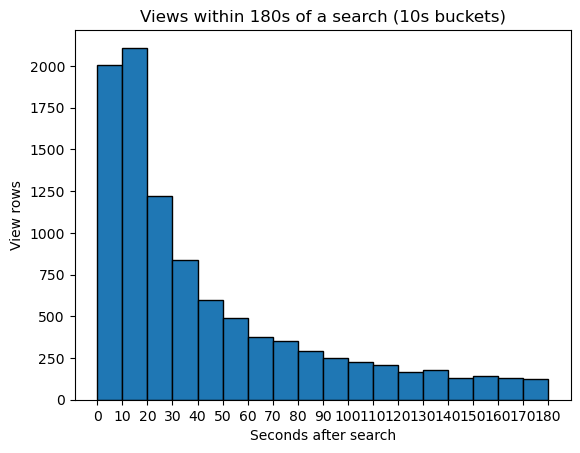

In [37]:
# find views that occur within time_interval seconds after a search by the same user
# when two searches happen in a row with no engagement between them, remove the first search (it clearly had no engagement)

s = search[['current_member_id', 'time', 'terms', 'request_id']].rename(columns={'time': 'search_time'})
v = post_views[
    ['current_member_id', 'time', ]
].rename(columns={'time': 'view_time'})

WINDOW = 180
BUCKET = 10

# Attach each engage row to the member's most recent search within WINDOW seconds
# merge_asof matches on the nearest key, so (because this is a left merge on engagements)
# this drops consecutive searches with no intervening engagements.
m = pd.merge_asof(
    v.sort_values('view_time'),
    s.sort_values('search_time'),
    left_on='view_time',
    right_on='search_time',
    by='current_member_id',
    direction='backward',
    tolerance=pd.Timedelta(seconds=WINDOW),
).dropna(subset=['search_time'])

m['delta_s'] = (m['view_time'] - m['search_time']).dt.total_seconds()

print(len(m))

plt.hist(m['delta_s'], bins=range(0, WINDOW + 5, BUCKET), edgecolor='black')
plt.xticks(range(0, WINDOW + 5, BUCKET))
plt.xlabel('Seconds after search')
plt.ylabel('View rows')
plt.title(f'Views within {WINDOW}s of a search ({BUCKET}s buckets)')
plt.show()

In [38]:
m[m['delta_s']<=120]['delta_s'].quantile([.05, .25, .5, .75, .95])

0.05     4.872
0.25    10.807
0.50    22.564
0.75    49.037
0.95    99.530
Name: delta_s, dtype: float64

In [39]:
# The effect of searches on views seems to fade after 120 seconds, and over half of the views after searches happen within 60 s.
VIEW_WINDOW = 60

In [40]:
# There are only about 9300 such views
len(m[m['delta_s']<=VIEW_WINDOW])

7257

In [41]:
# Only about 16% of searches are followed by a view within VIEW_WINDOW seconds.
len(m[m['delta_s']<=VIEW_WINDOW])/len(search)

0.1209399216731939

10789


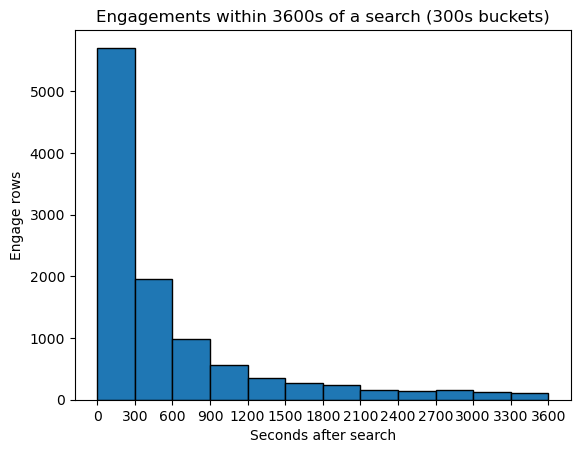

In [42]:
# find engagements that occur within time_interval seconds after a search by the same user
# when two searches happen in a row with no engagement between them, remove the first search (it clearly had no engagement)

s = search[['current_member_id', 'time', 'terms', 'request_id']].rename(columns={'time': 'search_time'})
e = engage[
    ['current_member_id', 'time', 'engagement_type', 'resource_name', 
     'post_is_question', 'post_content_subject', 'clean_content','post_id','content_id']
].rename(columns={'time': 'engage_time'})

WINDOW = 3600
BUCKET = 300

# Attach each engage row to the member's most recent search within WINDOW seconds
# merge_asof matches on the nearest key, so (because this is a left merge on engagements)
# this drops consecutive searches with no intervening engagements.
m = pd.merge_asof(
    e.sort_values('engage_time'),
    s.sort_values('search_time'),
    left_on='engage_time',
    right_on='search_time',
    by='current_member_id',
    direction='backward',
    tolerance=pd.Timedelta(seconds=WINDOW),
).dropna(subset=['search_time'])

m['delta_s'] = (m['engage_time'] - m['search_time']).dt.total_seconds()

print(len(m))

plt.hist(m['delta_s'], bins=range(0, WINDOW + 5, BUCKET), edgecolor='black')
plt.xticks(range(0, WINDOW + 5, BUCKET))
plt.xlabel('Seconds after search')
plt.ylabel('Engage rows')
plt.title(f'Engagements within {WINDOW}s of a search ({BUCKET}s buckets)')
plt.show()

In [43]:
# approximately 95% of engagements in the first 3600 seconds (1 hour) after searches 
# happen within 2400 seconds (40 minutes).

m[m['delta_s']<=WINDOW]['delta_s'].quantile([.05, .25, .5, .75, .95])

0.05      17.7598
0.25      98.1270
0.50     270.8480
0.75     704.2380
0.95    2399.5142
Name: delta_s, dtype: float64

In [44]:
ENGAGE_WINDOW = 2400

In [45]:
# There are about 10,000 such engagements.
len(m[m['delta_s']<=ENGAGE_WINDOW])

10249

In [46]:
# Only about 17% of searches are followed by an engagement within ENGAGE_WINDOW seconds.
len(m[m['delta_s']<=ENGAGE_WINDOW])/len(search)

0.17080243313057245

# Create positive search result datasets

#### Positive results type 1: Post had the right content

In [47]:
# users searches, views a post, then replies to or appreciates the post
# or, user views a resource, then appreciates or downloads the resource

post_engagements = engage[
    (engage['engagement_type'].isin(['Content Appreciation','Post Reply','Event RSVP','Poll Vote', 'Opportunity Application']))
    & (engage['post_id'] > 0)
][
    ['engagement_type', 'post_or_comment_content', 'post_is_question',
       'community_id', 'community_name', 'content_id', 'content_type',
       'current_member_id', 'reply_type', 'timestamp', 'post_id', 'post_type',
       'post_created_timestamp', 'resource_name', 'time']
]

# views that are engaged within ENGAGE_WINDOW
engaged_views = pd.merge_asof(
    post_engagements.rename(columns = {'time': 'engage_time'}).sort_values('engage_time').drop(columns = ['timestamp']),
    post_views.rename(columns = {'time': 'view_time'}).sort_values('view_time').drop(columns = ['timestamp', 'post_type']),
    left_on = 'engage_time',
    right_on = 'view_time', 
    by=['community_id', 'current_member_id', 'post_id'], # member views and engages with the same post.
    direction='backward',
    tolerance=pd.Timedelta(seconds=ENGAGE_WINDOW), # view_time up to WINDOW seconds before engagement time
).dropna(subset=['view_time'])

engaged_views['delta_s'] = (engaged_views['engage_time'] - engaged_views['view_time']).dt.total_seconds()

# merge_asof engaged_views backward on search (ENGAGE_WINDOW tolerance)

# engaged views in which the view happens within VIEW_WINDOW of a serach (this was set above)

engaged_search_results = pd.merge_asof(
    engaged_views.sort_values('view_time'),
    search.rename(columns = {'time': 'search_time'}).sort_values(
        'search_time'
    ).drop(columns = [
        'timestamp', 'community_name'
    ]),
    left_on = 'view_time',
    right_on = 'search_time',
    by=['community_id', 'current_member_id'],
    direction='backward',
    tolerance=pd.Timedelta(seconds=VIEW_WINDOW),
).dropna(subset=['search_time'])

engaged_search_results['delta_s'] = (engaged_search_results['engage_time'] - engaged_search_results['search_time']).dt.total_seconds()

len(engaged_search_results) # only about 300 results through this route. 

236

In [48]:
# there were about 3600 eligible views in the search window, so users are engaging with fewer than 10% of the viewed posts.
# we're surely missing some cases where the user found the right thing, but didn't give us any positive signal 
# (nothing forces them to appreciate or reply)

In [49]:
engaged_search_results.value_counts('community_id')

community_id
24553    95
44425    38
48187    30
47232    29
10552    18
19036    13
20048    13
Name: count, dtype: int64

#### Positive results type 2: Resource had the right subject / name

In [50]:
engage['is_resource'] = np.where(
    engage['resource_id'].isna(), False, True)

In [51]:
engage.value_counts(['is_resource','engagement_type'])

is_resource  engagement_type        
True         Resource Download          122816
False        Post Reply                  69149
             Content Appreciation        56987
             Event RSVP                  55259
             Post Created                26423
             Poll Vote                   16378
True         Resource View                9075
             Resource Added               4722
False        Opportunity Application       357
Name: count, dtype: int64

In [52]:
# now the same pattern for resources: 
# users searches, views a resource, then downloads the resource
resource_engagements = engage[engage['engagement_type']=='Resource Download']
resource_views = engage[engage['engagement_type'] == 'Resource View'][
    ['community_id','current_member_id','time','resource_id']
    ]

# resource views that are engaged within ENGAGE_WINDOW
engaged_resources = pd.merge_asof(
    resource_engagements.rename(columns = {'time': 'engage_time'}).sort_values('engage_time').drop(columns = ['timestamp']),
    resource_views.rename(columns = {'time': 'view_time'}).sort_values('view_time'),
    left_on = 'engage_time',
    right_on = 'view_time', 
    by=['community_id', 'current_member_id', 'resource_id'], # member views and engages with the same post.
    direction='backward',
    tolerance=pd.Timedelta(seconds=ENGAGE_WINDOW), # view_time up to WINDOW seconds before engagement time
).dropna(subset=['view_time'])

engaged_resources['delta_s'] = (engaged_resources['engage_time'] - engaged_resources['view_time']).dt.total_seconds()

In [53]:
# about 1/3 of viewed resources get engagements within the engagement window. 
# this seems less ironclad than post engagements because users have historically gotten less information about resources in the UI
# (they have to download the resource to read it)
len(engaged_resources) / len(resource_views)

0.34203856749311295

In [54]:
# of the results, searches that are viewed within VIEW_WINDOW
engaged_resource_results = pd.merge_asof(
    engaged_resources.sort_values('view_time'),
    search.rename(columns = {'time': 'search_time'}).sort_values(
        'search_time'
    ).drop(columns = [
        'timestamp', 'community_name'
    ]),
    left_on = 'view_time',
    right_on = 'search_time',
    by=['community_id', 'current_member_id'],
    direction='backward',
    tolerance=pd.Timedelta(seconds=VIEW_WINDOW),
).dropna(subset=['search_time'])

engaged_resource_results['delta_s'] = (engaged_search_results['engage_time'] - engaged_search_results['search_time']).dt.total_seconds()

len(engaged_resource_results)  

63

#### Positive results type 3: Post had the right subject / name

In [55]:
# users searches, then views a post 
# in this case, we can't trust that the post content is relevant. 
# when users make a search, they initially see results with only the subject line. 
# if they hit enter after entering the search terms, they see the post subject line and the first few lines of the post content. 
# these are not tracked as views: we don't get a view event until the user clicks on the post. 
# so the user has to view the post to see the full view. 

# so a view without an engagement does not tell us that the post content was relevant, 
# but we do have a signal that the post subject (all that is shown to the user in the search interface) looks right. 

# in this case, we should feed the (terms, post subject) to the model as a positive result. 


viewed_search_results = pd.merge_asof(
    post_views.rename(columns = {'time': 'view_time'}).sort_values('view_time').drop(columns = ['timestamp']),
    search.rename(columns = {'time': 'search_time'}).sort_values('search_time').drop(columns = ['timestamp']),
    left_on='view_time',
    right_on='search_time',
    by=['community_id', 'current_member_id'],
    direction='backward',
    tolerance=pd.Timedelta(seconds=VIEW_WINDOW),
).dropna(subset=['search_time'])

viewed_search_results['delta_s'] = (viewed_search_results['view_time'] - viewed_search_results['search_time']).dt.total_seconds()

len(viewed_search_results) # over 7000 results through this route. 

7257

In [56]:
# negative path 1: users searches, views a post or resource, then searches again without engaging 

In [57]:
# negative path 2: users searches, views a post or resource, then views another post/resource and engages with it. 

### Investigation of Posts Created that are asking questions after searches

In [122]:
# (commenting this out to avoid risk of PII shared via Github - see next cell for selected examples)

# 'Post Created' after the search is often a question post to make up for a missed search...hm.
# m[
#     (m['engagement_type']=='Post Created') & (m['post_is_question'] == 'Question') &
#     (m['delta_s'] > 80) & (m['delta_s'] < 160)
    
# ][
#     ['terms','engagement_type','post_content_subject','resource_name','delta_s', 'post_is_question']
# ]
# almost all of the posts created within 80 seconds look related to the search query.

In [123]:
# examples of posts found in previous cell
m.loc[
    [359292, 249978, 323592, 254649, 346455]
][
    ['terms','engagement_type','post_content_subject','resource_name','delta_s', 'post_is_question']
] 

,terms,engagement_type,post_content_subject,resource_name,delta_s,post_is_question
359292,electronic fee tickets,Post Created,Electronic Fee tickets,NaN,95.359,Question
249978,avastin,Post Created,Avastin,NaN,146.770,Question
323592,hospice,Post Created,Hospice Palliative Care vs End of Life Care,NaN,141.978,Question
254649,per ride fee access,Post Created,Voiding per trip fees for access/equity rides?,NaN,143.028,Question
346455,bedside report,Post Created,Bedside Shift Report in the Labor and Delivery...,NaN,102.195,Question


### Create paired question - response dataset

In [65]:
# when a post matches the "one word from the dataset" rule 
# or it is marked as a question by the ML 
# look for comments that are appreciated by the post author 
# these become question-response pairs

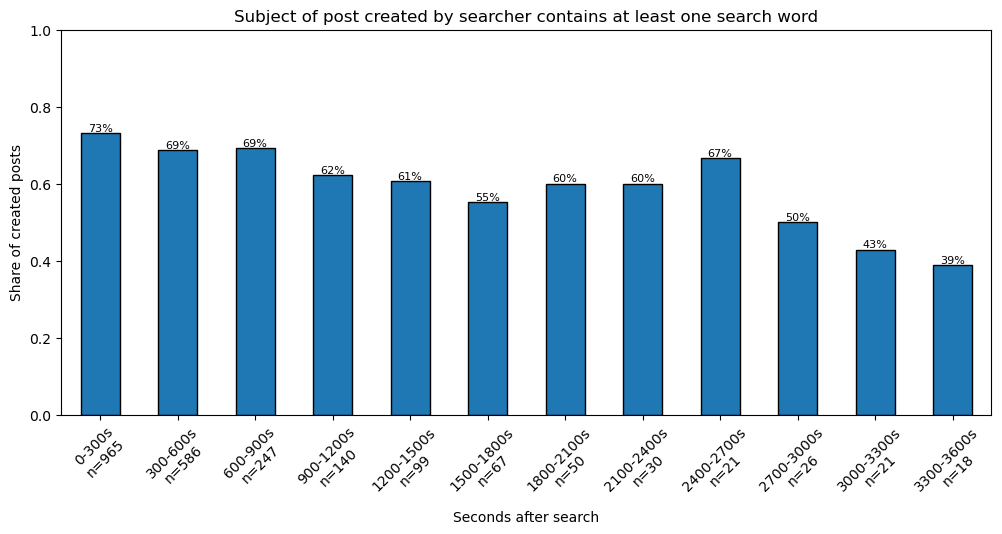

In [66]:
WINDOW = 3600
BUCKET = 300
intervals = list(range(BUCKET, WINDOW + BUCKET, BUCKET))
edges = [0] + intervals
labels = [f'{a}-{b}s' for a, b in zip(edges[:-1], edges[1:])]

p = m[m['engagement_type'] == 'Post Created'].copy()

# match on cases where the subject of the created post contains at least one word  
# from the search terms, excluding common 'stop' words
term_words = p['terms'].fillna('').str.lower().map(lambda t: set(re.findall(r'\w+', t)))
STOP = {'the', 'a', 'an', 'and', 'or', 'of', 'to', 'in', 'for', 'on', 'how', 'what', 'is', 'do', 'i'}
term_words = term_words.map(lambda t: t - STOP)
subj_words = p['post_content_subject'].fillna('').str.lower().map(lambda s: set(re.findall(r'\w+', s)))
p['match'] = [bool(t & s) for t, s in zip(term_words, subj_words)]

p['bucket'] = pd.cut(
    p['delta_s'], edges,
    labels=labels, include_lowest=True,
)

g = p.groupby('bucket', observed=False).agg(
    word_match=('match', 'mean'),
    n=('match', 'size'),
)

ax = g['word_match'].plot.bar(edgecolor='black', rot=45, figsize=(12, 5))
ax.bar_label(ax.containers[0], fmt=lambda v: f'{v:.0%}', fontsize=8)
ax.set_xticklabels([f'{lbl}\nn={n}' for lbl, n in zip(g.index, g['n'])])
ax.set_ylabel('Share of created posts')
ax.set_xlabel('Seconds after search')
ax.set_title('Subject of post created by searcher contains at least one search word')
ax.set_ylim(0, 1)
plt.show()

In [67]:
p.columns

Index(['current_member_id', 'engage_time', 'engagement_type', 'resource_name',
       'post_is_question', 'post_content_subject', 'clean_content', 'post_id',
       'content_id', 'search_time', 'terms', 'request_id', 'delta_s', 'match',
       'bucket'],
      dtype='object')

In [68]:
len(p)

2270

In [69]:
# this is the set of Post Created events that match the criteria
questions = p[(p['match'])].copy()

In [70]:
questions['engagement_type'].unique()

array(['Post Created'], dtype=object)

In [71]:
# this query gets replies to the questions
replies = engage[
    (engage['engagement_type'] != 'Post Created') & 
    (engage['engagement_type'] == 'Post Reply') & 
    (engage['reply_type'] != 'Private Reply') & # we don't have content for these, so they are useless to this project.
    (engage['post_id'].isin(questions['post_id'].unique()))
].copy()

In [72]:
len(questions)

1554

In [73]:
len(replies)

4980

In [74]:
# now filter to just the replies appreciated by the original questioners

In [75]:
engage['engagement_type'].unique()

array(['Content Appreciation', 'Resource Download', 'Resource Added',
       'Resource View', 'Post Created', 'Post Reply', 'Event RSVP',
       'Poll Vote', 'Opportunity Application'], dtype=object)

In [76]:
# appreciations of the replies
appreciations = engage[
    (engage['engagement_type'] == 'Content Appreciation') & 
    (engage['content_type'] != 'post') &
    (engage['content_id'].isin(replies['content_id']))
].copy()

In [77]:
len(questions)

1554

In [78]:
len(replies)

4980

In [79]:
len(appreciations)

1645

In [80]:
questions.drop(columns = ['content_id'], inplace = True)

In [82]:
# Post - reply - appreciation

# Original post (announcement about a new course) has a post_id 
# Join to comments by looking for comments with that post_id 

# Join to appreciations by looking for appreciations with each comment’s content_id

reply_appreciations = replies[['post_id','content_id','clean_content']].merge(
    appreciations[['content_id','current_member_id']].rename(
        columns = {'current_member_id': 'appreciator'}
    ),
    how = 'inner',
    on = 'content_id'
)
len(reply_appreciations)

1645

In [83]:
questions.columns

Index(['current_member_id', 'engage_time', 'engagement_type', 'resource_name',
       'post_is_question', 'post_content_subject', 'clean_content', 'post_id',
       'search_time', 'terms', 'request_id', 'delta_s', 'match', 'bucket'],
      dtype='object')

In [84]:
valid_replies = questions.rename(
    columns = {'clean_content': 'post_created_content'}
).merge(
    reply_appreciations[['post_id','content_id','appreciator','clean_content']],
    how = 'inner',
    left_on = ['post_id', 'current_member_id'],
    right_on = ['post_id', 'appreciator'] # the appreciator matches the original poster
)

In [85]:
len(valid_replies)

453

In [86]:
valid_replies.columns

Index(['current_member_id', 'engage_time', 'engagement_type', 'resource_name',
       'post_is_question', 'post_content_subject', 'post_created_content',
       'post_id', 'search_time', 'terms', 'request_id', 'delta_s', 'match',
       'bucket', 'content_id', 'appreciator', 'clean_content'],
      dtype='object')

In [87]:
# checking results (commented out to avoid sharing PII on Github)

# for index, row in valid_replies.sample(3).iterrows():
#     print('------------')
#     print('SEARCH TERMS:')
#     print(row['terms'])
#     print()
#     print('SUBJECT:')
#     print(row['post_content_subject'])
#     print()
#     print('POST CONTENT:')
#     print(row['post_created_content'])
#     print()
#     print('APPRECIATED COMMENT:')
#     print(row['clean_content'])
#     print()

In [88]:
engage.columns

Index(['engagement_type', 'post_or_comment_content', 'post_is_question',
       'community_id', 'community_name', 'content_id', 'content_type',
       'current_member_id', 'reply_type', 'timestamp', 'post_id', 'post_type',
       'post_created_timestamp', 'post_content_subject', 'resource_id',
       'resource_name', 'clean_content', 'time', 'is_resource'],
      dtype='object')

In [89]:
engage['community_id'].value_counts()

community_id
44425    118483
24553     88527
10552     57765
20048     44676
19036     25057
48187     16488
47232     10170
Name: count, dtype: int64

In [90]:
len(engaged_search_results)

236

In [91]:
len(engaged_resource_results)

63

In [92]:
len(viewed_search_results)

7257

In [93]:
len(valid_replies)

453

## Summary of dataset construction
We now have four types of positive results:
| Type | Number of rows | Notes |
|----------|----------|----------|
| User searched, viewed post and engaged with it  | 236  | High confidence that content matched search  |
| User searched, viewed resource and downloaded it  | 63  | Low confidence that content matched search  |
| User searched and viewed post | 7257  | Low confidence that content matched search  |
| User searched, created a post that asked a question in the search term, and appreciated a reply | 453  | High confidence that content matched search   |

# Concatenate the posts

In [94]:
engaged_search_results['signal_type'] = 'engaged'
engaged_resource_results['signal_type'] = 'engaged'
viewed_search_results['signal_type'] = 'viewed'
valid_replies['signal_type'] = 'post_created'

In [95]:
positives = pd.concat([
    engaged_search_results,
    engaged_resource_results,
    viewed_search_results,
    valid_replies,
])

# Scrub PII 

In [97]:
string_cols = positives.select_dtypes(include=['object', 'string']).columns.tolist()
print(string_cols)

['engagement_type', 'post_or_comment_content', 'post_is_question', 'community_name', 'content_type', 'reply_type', 'post_type', 'post_created_timestamp', 'resource_name', 'post_viewed_id', 'post_content_subject', 'clean_content', 'channel', 'permissions', 'request_id', 'search_context', 'terms', 'platform', 'substring', 'signal_type', 'is_resource', 'post_created_content', 'match']


In [98]:
positives.drop(columns = ['post_or_comment_content'], inplace = True)

In [99]:
columns_to_scrub = ['clean_content', 'post_created_content']

In [100]:
# - Code adapted from https://medium.com/@heshanhfernando/pii-masking-with-python-using-ai4privacy-12279bf7312a .

def load_model(model_tag: str, use_gpu: bool = False) -> Optional[Pipeline]:
    device = 0 if use_gpu else -1
    try:
        model = pipeline("token-classification", model=model_tag, tokenizer=model_tag, device=device)
        return model
    except Exception as e:
        print(f"Error loading Model: \n\n{e}")
        return None


def create_entity_map(model_output: List[dict], text: str) -> dict:
    entity_map = {}
    for token in model_output:
        start = token["start"]
        end = token["end"]
        entity = text[start: end]
        entity_map[entity] = token["entity_group"]
    return entity_map

def replace_entities(text: str, entity_map: dict, skip_classes: list) -> str:
    for word in entity_map:
        this_class = f"[{entity_map[word]}]"
        if word in text and this_class not in skip_classes:
            text = text.replace(word, f"[{entity_map[word]}]")
    return text

def mask_pii(input_sentence: str, anonymizer: Pipeline, skip_classes = []) -> Optional[str]:
    output = anonymizer(input_sentence, aggregation_strategy="simple")
    if isinstance(output, list):
        entity_map = create_entity_map(output, input_sentence)
        return replace_entities(input_sentence, entity_map, skip_classes)
    else:
        print("Output is not in the expected format")
    return None

# some classes, particularly currency codes, get overused by this model. 
# Add them to this list. They'll be skipped when the model identifies them. 
skip_classes = ['[CURRENCYCODE]', '[CURRENCYSYMBOL]', '[JOBAREA]', '[CREDITCARDCVV]', '[STATE]', '[FIRSTNAME]', '[LASTNAME]',
                '[MIDDLENAME]', '[EYECOLOR]', '[AGE]', '[COMPANYNAME]', '[SSN]', '[PIN]', '[SECONDARYADDRESS]',
               '[VEHICLEVRM]', '[DOB]', '[IPV4]', '[USERAGENT]']
# The model often sees emoji as currency codes and symbols
# We have a valid interest in job areas, states, and company names (many questions are about companies and states). 
# The model sees three-digit strings as credit card CVVs - which they very commonly (probably always) are not. 
# First name and last name have a big risk of false positives (e.g., mathematicians searching for "Pascal"), 
# ...so we'll scrub those by scrubbing against the list of community member names instead. 
# Eye color, age, and SSN are almost always false positives in this dataset (Medicare codes being discussed by ophthamologists
# are often coded as a PII number like SSN, age, or zip code).

# Example usage with real data

# this downloads the model locally.
anonymizer_model = load_model("Isotonic/distilbert_finetuned_ai4privacy_v2")


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

In [101]:
scrub_these = positives.sample(100).copy()

In [102]:
# apply the function call to these posts, populating the scrubbed data column for them
def scrub(this_text, this_model, skip_classes):
    this_text = str(this_text)

    if this_model:
        try: 
            masked_text = mask_pii(this_text, this_model, skip_classes)
            # print(masked_text)
            return(masked_text)
        except Exception as e:
            print(f"Error calling model: \n\n{e}")
            return None
    else:
        print("Anonymizer model not found.")
        return None
    
# about 1.4s per 100 posts
%time scrub_these['scrubbedText'] = scrub_these['clean_content'].apply(scrub, args = [anonymizer_model, skip_classes])

CPU times: user 1.72 s, sys: 829 ms, total: 2.55 s
Wall time: 1.77 s


In [103]:
for col in columns_to_scrub:
    positives['scrub_' + col] = positives[col].apply(scrub, args = [anonymizer_model, skip_classes])

In [104]:
positives.columns

Index(['engagement_type', 'post_is_question', 'community_id', 'community_name',
       'content_id', 'content_type', 'current_member_id', 'reply_type',
       'post_id', 'post_type', 'post_created_timestamp', 'resource_name',
       'engage_time', 'post_viewed_id', 'view_time', 'post_content_subject',
       'clean_content', 'delta_s', 'index', 'user_id', 'channel',
       'permissions', 'request_id', 'search_context', 'result_count', 'terms',
       'platform', 'search_time', 'minute', 'substring', 'signal_type',
       'resource_id', 'is_resource', 'post_created_content', 'match', 'bucket',
       'appreciator', 'scrub_clean_content', 'scrub_post_created_content'],
      dtype='object')

#### Filter out names of real users

In [105]:
names = pd.read_csv('names.csv')

In [106]:
names.columns

Index(['community_id', 'first_name', 'last_name'], dtype='object')

In [107]:
# the only PII we're concerned about in search terms is personal names
# (whereas the ML scrubbing would have just messed up this field)
# so I add it here.
positives["scrub_terms"] = positives["terms"]

In [108]:
WORD = re.compile(r"[^\W\d_]+")  # runs of letters, Unicode-aware

exclude = set("watt") 

# unfortunately some of the firstname and lastname fields contain words like "The" and "Hello."
# the next few lines strip common English words out of the first and last names.
from wordfreq import top_n_list

common = set(top_n_list("en", 10000))

CREDENTIALS = {"md", "do", "phd", "rn", "np", "pa", "ob", "dds", "dmd", "mph", "mba",
               "jr", "sr", "ii", "iii", "facs", "faap", "pe", "cpa"}

def _parts(name: str) -> list:
    name = name.split(",")[0]
    toks = WORD.findall(name)
    if not name.isupper():
        toks = [t for t in toks if not t.isupper()]
    return toks

def name_parts(s: pd.Series) -> set:
    parts = s.dropna().astype(str).map(_parts).explode().dropna().str.lower()
    return set(parts[parts.str.len() > 1]) - CREDENTIALS

def part_counts(s: pd.Series) -> pd.Series:
    return s.dropna().astype(str).map(_parts).explode().dropna().str.lower().value_counts()

counts = part_counts(names["first_name"]).add(part_counts(names["last_name"]), fill_value=0)

MIN_NAME_COUNT = 5  # how many times a common word has to show up in the name list before we treat it as a name.
manual = {"pascal"}  # argot allowlist
exclude = {w for w in common if counts.get(w, 0) < MIN_NAME_COUNT} | manual

def build_lookup(g: pd.DataFrame) -> dict:
    lookup = {n: "[LAST_NAME]" for n in name_parts(g["last_name"]) - exclude}
    lookup.update({n: "[FIRST_NAME]" for n in name_parts(g["first_name"]) - exclude})
    return lookup

lookups = {cid: build_lookup(g) for cid, g in names.groupby("community_id")}

def scrub_names(text: str, lookup: dict) -> str:
    def _sub(m: re.Match) -> str:
        w = m.group()
        return lookup.get(w.lower(), w) if w[0].isupper() else w
    return WORD.sub(_sub, text)

df = positives.reset_index(drop=True)
for col in (columns_to_scrub + ['terms']):
    scol = "scrub_" + col
    scrubbed = [
        g[scol].map(lambda t, lk=lookups.get(cid, {}): scrub_names(t, lk))
        for cid, g in df.dropna(subset=[scol]).groupby("community_id", dropna=False)
    ]
    df[scol] = pd.concat(scrubbed)

In [109]:
# checking results (commented out to avoid sharing PII on Github)

# for index, row in df.sample(10).iterrows():
#     print('------------')
#     print('SEARCH TERMS:')
#     print(row['terms'])
#     print()
#     print('SCRUBBED SEARCH TERMS:')
#     print(row['scrub_terms'])
#     print()
#     print('ORIGINAL:')
#     print(row['clean_content'])
#     print()
#     print('SCRUBBED:')
#     print(row['scrub_clean_content'])
#     print()

In [110]:
positives = df.copy()

In [111]:
positives.drop_duplicates(subset = ['post_id'])['scrub_clean_content'].str.len().median()

375.0

In [112]:
positives.drop_duplicates(subset = ['post_id'])['scrub_clean_content'].str.len().mean()

np.float64(440.72630143214366)

In [113]:
441/160

2.75625

In [114]:
len(positives.drop_duplicates(subset = ['post_id']))

4399

In [115]:
positives.to_csv('positives.csv')